In [2]:
# Bootstrap utilities

try:
    from rich import pretty, print
    pretty.install()
except ImportError:
    print("Module 'rich' not found, run uv sync or uv add rich to support rich printing")

try:
    from timeit_decorator import timeit_sync
except ImportError:
    print("Module 'timeit_decorator' not found, run uv sync or uv add timeit_decorator")

1. The MickeyMouse problem

a) Write a program that prints the numbers from 1 to 100. But for multiples of 3 print `Mickey` instead of the corresponding number and for the multiples of 5 print `Mouse`. For numbers which are multiples of both three and five print `MickeyMouse`

b) Put the result in a tuple and substitute `Mickey` with `Donald` and `Mouse` with `Duck`

In [1]:
# Generator assembly
fast_assemly = (
    "MickeyMouse" if i % 3 == 0 and i % 5 == 0 else
    "Mickey" if i % 3 == 0 else
    "Mouse" if i % 5 == 0 else
    None for i in range(100)
)

# Materialize
result_a = (list(filter(None, fast_assemly)))
print(result_a)

# b)
replace = lambda x: "Donald" if x == "Mickey" else ("Duck" if x == "Mouse" else ("DonaldDuck" if x == "MickeyMouse" else x))

assert replace("Mickey") == "Donald"
assert replace("Mouse") == "Duck"
assert replace("MickeyMouse") == "DonaldDuck" # Not sure if required
assert replace("nawfaf") == "nawfaf"

result_b = list(map(replace, result_a))
print(result_b)


['MickeyMouse', 'Mickey', 'Mouse', 'Mickey', 'Mickey', 'Mouse', 'Mickey', 'MickeyMouse', 'Mickey', 'Mouse', 'Mickey', 'Mickey', 'Mouse', 'Mickey', 'MickeyMouse', 'Mickey', 'Mouse', 'Mickey', 'Mickey', 'Mouse', 'Mickey', 'MickeyMouse', 'Mickey', 'Mouse', 'Mickey', 'Mickey', 'Mouse', 'Mickey', 'MickeyMouse', 'Mickey', 'Mouse', 'Mickey', 'Mickey', 'Mouse', 'Mickey', 'MickeyMouse', 'Mickey', 'Mouse', 'Mickey', 'Mickey', 'Mouse', 'Mickey', 'MickeyMouse', 'Mickey', 'Mouse', 'Mickey', 'Mickey']
['DonaldDuck', 'Donald', 'Duck', 'Donald', 'Donald', 'Duck', 'Donald', 'DonaldDuck', 'Donald', 'Duck', 'Donald', 'Donald', 'Duck', 'Donald', 'DonaldDuck', 'Donald', 'Duck', 'Donald', 'Donald', 'Duck', 'Donald', 'DonaldDuck', 'Donald', 'Duck', 'Donald', 'Donald', 'Duck', 'Donald', 'DonaldDuck', 'Donald', 'Duck', 'Donald', 'Donald', 'Duck', 'Donald', 'DonaldDuck', 'Donald', 'Duck', 'Donald', 'Donald', 'Duck', 'Donald', 'DonaldDuck', 'Donald', 'Duck', 'Donald', 'Donald']


2\. The swap function

Write a function that swap the values of two input variables x and y (whatever the type). Try to do that also without a temporary variable

In [18]:
from typing import Any

a: Any = 10
b: Any = "WJF"

print(a,b)

a, b = b, a
print(a,b)

10 WJF
WJF 10


3\. Computing the distance

Write a function that calculates and returns the euclidean distance between two points *u* and *v*, where *u* and *v* are both 2-tuples *(x,y)*. For example, if *u=(3,0)* and *v=(0,4)*, the function should return 5

In [11]:
@timeit_sync(runs=10)
def eudclidean_distance(point1: tuple[float, float], point2: tuple[float, float]) -> float:
    """Calculate the Euclidean distance between two points in 2D space."""
    return ((point1[0] - point2[0]) ** 2 + (point1[1] - point2[1]) ** 2) ** 0.5

assert eudclidean_distance((3, 0), (0, 4)) == 5.0
assert eudclidean_distance((0, 0), (3, 4)) == 5.0
assert eudclidean_distance((1, 2), (4, 6)) == 5.0
assert eudclidean_distance((0,0), (0,0)) == 0.0

2026-10-09 13:39:11 [INFO] (timeit.decorator) eudclidean_distance: Avg: 1.00µs, Med: 0.95µs
2026-10-09 13:39:11 [INFO] (timeit.decorator) eudclidean_distance: Avg: 0.93µs, Med: 0.48µs
2026-10-09 13:39:11 [INFO] (timeit.decorator) eudclidean_distance: Avg: 0.79µs, Med: 0.48µs
2026-10-09 13:39:11 [INFO] (timeit.decorator) eudclidean_distance: Avg: 0.57µs, Med: 0.00µs


4\. Counting letters

Write a program to calculate the number of times each character occurs in a given string *s*. Ignore differneces in capitalization

/Users/noelschwabenland/Repositories/lpc/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

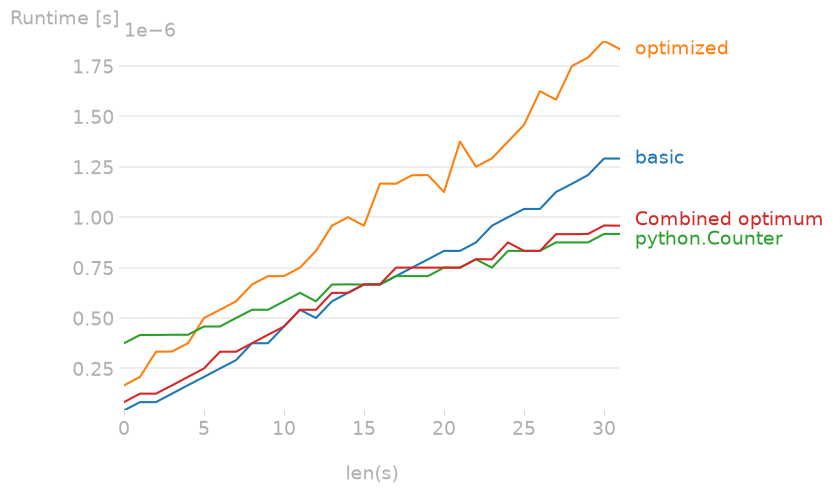

In [22]:


s="Write a program that prints the numbers from 1 to 100. \
But for multiples of three print Mickey instead of the number and for the multiples of five print Mouse. \
For numbers which are multiples of both three and five print MickeyMouse"

# @timeit_sync(runs=100_000)
def count_letters(string_s: str, case_sensitive: bool = False) -> dict[str, int]:
    """Count the occurrences of each letter in a string."""
    seen_letters: dict[str, int] = {}
    string_s = string_s if case_sensitive else string_s.lower()
    for letter in string_s:
        if letter in seen_letters:
            seen_letters[letter] += 1
        else:
            seen_letters[letter] = 1

    return seen_letters

# @timeit_sync(runs=100_000, detailed=True)
def count_letters_fast(string_s: str, case_sensitive: bool = False) -> dict[str, int]:
    s_lower = string_s.lower()
    seen_letters: dict[str, int] = {seen: 0 for seen in set(s_lower)} # Alreaddy initialized
    for l in s_lower: seen_letters[l] += 1
    return seen_letters


from collections import Counter

### Fastest Way Only
# @timeit_sync(runs=100_000, detailed=True)
def count_letters_faster(string_s: str) -> dict[str, int]:
    return Counter(string_s.lower())


# count_1 = count_letters(s)
# count_2 = count_letters_fast(s)
# count_letters_faster(s)

def fwa_combination(string_s: str) ->  dict[str, int]:
    if len(string_s) <= 16:
        return count_letters(string_s)

    return count_letters_faster(string_s)


import numpy as np
import perfplot
alphabet = np.array(list("abcdefghijklmnopqrstuvwxyz0123456789"))
perfplot.show(
    setup=lambda n: "".join(np.random.default_rng().choice(alphabet, size=n)),  # or setup=np.random.rand
    kernels=[
        lambda a: count_letters(a),
        lambda a: count_letters_fast(a),
        lambda a: count_letters_faster(a),
        lambda a: fwa_combination(a)
    ],
    labels=["basic", "optimized", "python.Counter", "Combined optimum"],
    n_range=[k for k in range(32)],
    xlabel="len(s)",
    equality_check=False,
    # More optional arguments with their default values:
    # logx="auto",  # set to True or False to force scaling
    # logy="auto",
    # equality_check=np.allclose,  # set to None to disable "correctness" assertion
    show_progress=True,
    # target_time_per_measurement=1.0,
    # max_time=None,  # maximum time per measurement
    # time_unit="s",  # set to one of ("auto", "s", "ms", "us", or "ns") to force plot units
    # relative_to=1,  # plot the timings relative to one of the measurements
    # flops=lambda n: 3*n,  # FLOPS plots
)

5\. Isolating the unique

Write a function that determines and count the unique numbers in the list *l*

In [ ]:
l = [36, 45, 58, 3, 74, 96, 64, 45, 31, 10, 24, 19, 33, 86, 99, 18, 63, 70, 85,
 85, 63, 47, 56, 42, 70, 84, 88, 55, 20, 54, 8, 56, 51, 79, 81, 57, 37, 91,
 1, 84, 84, 36, 66, 9, 89, 50, 42, 91, 50, 95, 90, 98, 39, 16, 82, 31, 92, 41,
 45, 30, 66, 70, 34, 85, 94, 5, 3, 36, 72, 91, 84, 34, 87, 75, 53, 51, 20, 89, 51, 20]

# Using old code
unique = sorted([k for k, v in list(filter((lambda kv: kv[1] == 1), count_letters(l, True).items()))])
non_unique = sorted([k for k, v in list(filter((lambda kv: kv[1] != 1), count_letters(l, True).items()))])

# FWO
print(set(n for n, o in Counter(l).items() if o == 1))

# Smart way
# TODO

{
    1,
    5,
    8,
    9,
    10,
    16,
    18,
    19,
    24,
    30,
    33,
    37,
    39,
    41,
    47,
    53,
    54,
    55,
    57,
    58,
    64,
    72,
    74,
    75,
    79,
    81,
    82,
    86,
    87,
    88,
    90,
    92,
    94,
    95,
    96,
    98,
    99
}

6\. Combination of functions

Write two functions - one that returns the square of a number, and one that returns the cube. Now write a third function that returns the number raised to the 6th power using the two previous functions.

In [26]:
def square(number: float) -> float:
    return number**2

def cube(number: float) -> float:
    return number**3

def sixth_power(number: float) -> float:
    return cube(square(number))

assert square(2) == 4
assert cube(2) == 8
assert sixth_power(2) == 64

7\. Cubes

Create a list of the cubes of x for x in *[0, 10]* using:

a) a for loop

b) a list comprehension

In [ ]:
# Solution a)
a_cube = []

for x in range(0, 10):
    a_cube.append(x**3)

# Solution b)
b_cube = [x**3 for x in range(0, 10)]

assert a_cube == b_cube
print(a_cube)
print(b_cube)

[0, 1, 8, 27, 64, 125, 216, 343, 512, 729]

[0, 1, 8, 27, 64, 125, 216, 343, 512, 729]


8\. Nested list comprehension

A Pythagorean triple is an integer solution to the Pythagorean theorem $a^2+b^2=c^2$. The first Pythagorean triple is (3,4,5). Find and put in a tuple all unique Pythagorean triples for the positive integers a, b and c less than 100.

In [ ]:
@timeit_sync(runs=100)
def first_implementation():

    pyth = set()

    for a in range(1,100):
        for b in range(1,100):
            for c in range(1,100):
                if a**2 + b**2 == c**2:
                    pyth.add((a,b,c))

    return pyth



# FWO
@timeit_sync(runs=100)
def second_implementation():
    """
    a**2 + b**2 = c**2
    given c:
    for all a < c:
        for all b for a < b < c:
            check if a**2 + b**2 = c**2 applies
    """
    triples = tuple(
        (a, b, c)
        for c in range(1, 100)
        for a in range(1, c)
        for b in range(a, c)
        if a * a + b * b == c * c
    )
    return triples


first_implementation()
second_implementation() # ~10x faster



2026-10-09 13:28:21 [INFO] (timeit.decorator) first_implementation: Avg: 74.60ms, Med: 73.51ms
2026-10-09 13:28:22 [INFO] (timeit.decorator) second_implementation: Avg: 7.86ms, Med: 7.77ms



(
    (3, 4, 5),
    (6, 8, 10),
    (5, 12, 13),
    (9, 12, 15),
    (8, 15, 17),
    (12, 16, 20),
    (7, 24, 25),
    (15, 20, 25),
    (10, 24, 26),
    (20, 21, 29),
    (18, 24, 30),
    (16, 30, 34),
    (21, 28, 35),
    (12, 35, 37),
    (15, 36, 39),
    (24, 32, 40),
    (9, 40, 41),
    (27, 36, 45),
    (14, 48, 50),
    (30, 40, 50),
    (24, 45, 51),
    (20, 48, 52),
    (28, 45, 53),
    (33, 44, 55),
    (40, 42, 58),
    (36, 48, 60),
    (11, 60, 61),
    (16, 63, 65),
    (25, 60, 65),
    (33, 56, 65),
    (39, 52, 65),
    (32, 60, 68),
    (42, 56, 70),
    (48, 55, 73),
    (24, 70, 74),
    (21, 72, 75),
    (45, 60, 75),
    (30, 72, 78),
    (48, 64, 80),
    (18, 80, 82),
    (13, 84, 85),
    (36, 77, 85),
    (40, 75, 85),
    (51, 68, 85),
    (60, 63, 87),
    (39, 80, 89),
    (54, 72, 90),
    (35, 84, 91),
    (57, 76, 95),
    (65, 72, 97)
)

9\. Normalization

Write a function that takes a tuple of numbers and returns it with the entries normalized to one

In [64]:
def normalize(target: tuple) -> tuple:
    return tuple(x / len(target) for x in target)
